In [ ]:

import pandas as pd

url = "https://ourworldindata.org/grapher/population.csv?download-format=full"

df = pd.read_csv(
    url,
    storage_options={"User-Agent": "Mozilla/5.0"}
)

df.head()



,Entity,Code,Year,Population
0,Afghanistan,AFG,-10000,14737
1,Afghanistan,AFG,-9000,20405
2,Afghanistan,AFG,-8000,28253
3,Afghanistan,AFG,-7000,39120
4,Afghanistan,AFG,-6000,54166


In [ ]:

# Check the dataset
print("Dataset shape:", df.shape)

print("\nColumn information:")
df.info()

print("\nLatest available year:", df["Year"].max())

print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (58824, 4)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58824 entries, 0 to 58823
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Entity      58824 non-null  object
 1   Code        58629 non-null  object
 2   Year        58824 non-null  int64 
 3   Population  58824 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 1.8+ MB

Latest available year: 2023

Missing values:
Entity          0
Code          195
Year            0
Population      0
dtype: int64


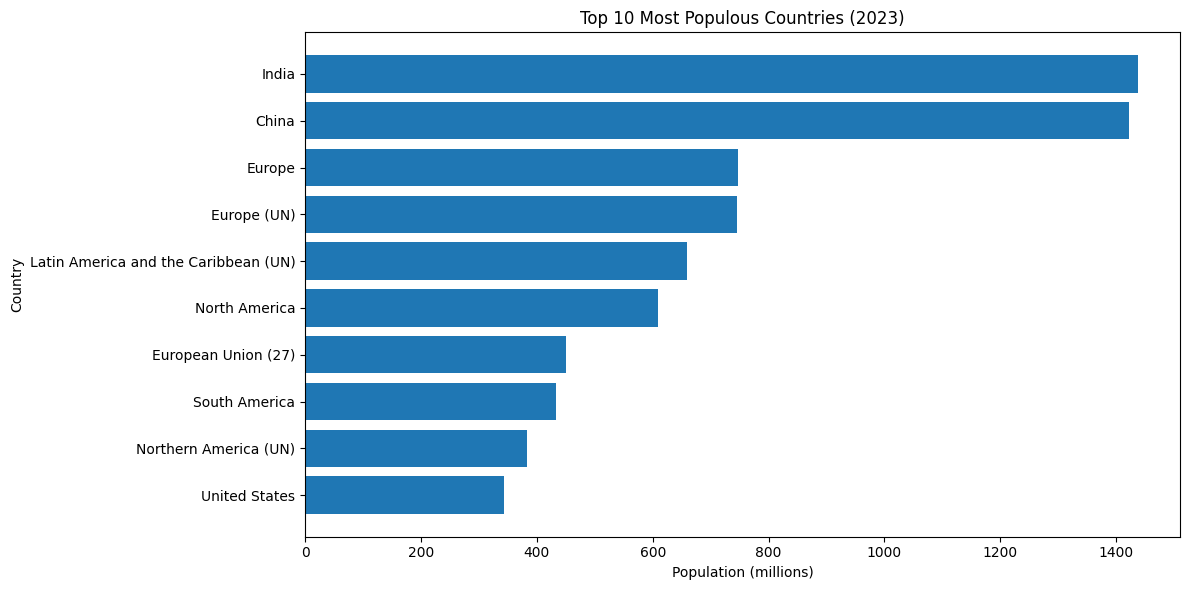

In [16]:

# Select the latest available year
latest_year = df["Year"].max()
latest_data = df[df["Year"] == latest_year].copy()


# Keep individual countries and exclude known aggregates
aggregates = [
    "World", "Asia (UN)", "Asia",
    "Africa (UN)", "Africa",
    "Upper-middle-income countries",
    "Lower-middle-income countries",
    "High-income countries",
    "Low-income countries"
]

countries = latest_data[
    latest_data["Code"].notna()
    & latest_data["Population"].notna()
    & ~latest_data["Entity"].isin(aggregates)
].copy()

top_10 = countries.nlargest(10, "Population").sort_values("Population")


top_10 = countries.nlargest(10, "Population")
top_10 = top_10.sort_values("Population")

plt.figure(figsize=(12, 6))
plt.barh(
    top_10["Entity"],
    top_10["Population"] / 1_000_000
)

plt.title(f"Top 10 Most Populous Countries ({latest_year})")
plt.xlabel("Population (millions)")
plt.ylabel("Country")
plt.tight_layout()

# Save BEFORE displaying
plt.savefig("top_10_population.png", dpi=300, bbox_inches="tight")
plt.show()


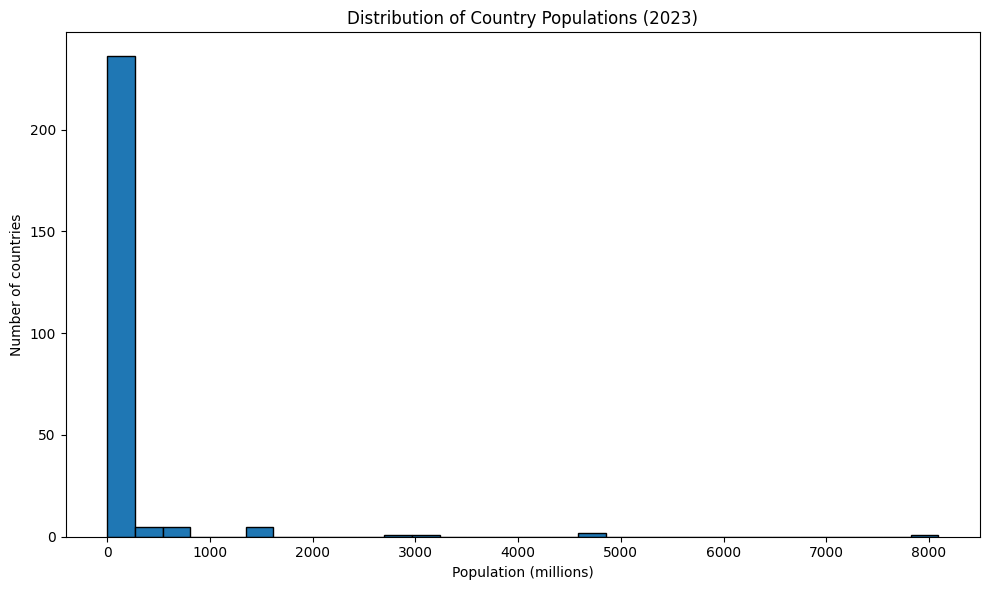

In [ ]:

plt.figure(figsize=(10, 6))

plt.hist(
    countries["Population"] / 1_000_000,
    bins=30,
    edgecolor="black"
)

plt.title(f"Distribution of Country Populations ({latest_year})")
plt.xlabel("Population (millions)")
plt.ylabel("Number of countries")
plt.tight_layout()

# Save BEFORE displaying
plt.savefig("population_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:

import os

print(os.path.exists("top_10_population.png"))
print(os.path.exists("population_distribution.png"))


True
True


In [ ]:

from google.colab import files

files.download("top_10_population.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

files.download("population_distribution.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>